In [8]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:")
print(PROJECT_ROOT)

DATA_ROOT = PROJECT_ROOT / "data" / "raw"

print("\nRaw data:")
print(DATA_ROOT)

print("\nContents:")
for item in DATA_ROOT.iterdir():
    print(item.name)

Project root:
d:\Sanika_EGM_Project

Raw data:
d:\Sanika_EGM_Project\data\raw

Contents:
annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0
annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0.zip


In [9]:
dataset_candidates = list(DATA_ROOT.rglob("ARGODataset_Folder"))

print("ARGO folders found:")

for folder in dataset_candidates:
    print(folder)

ARGO folders found:
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder


In [10]:
ARGO_ROOT = dataset_candidates[0]

print("ARGO dataset:")
print(ARGO_ROOT)

ARGO dataset:
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder


In [11]:
patient_dirs = [
    p for p in ARGO_ROOT.iterdir()
    if p.is_dir() and p.name.lower().startswith("pt")
]

print("Number of patient folders:", len(patient_dirs))

print("\nPatient folders:")
for p in patient_dirs:
    print(p.name)

Number of patient folders: 9

Patient folders:
Pt1
Pt2
Pt3
Pt4
Pt5
Pt6
Pt7
Pt8
Pt9


In [12]:
for patient in patient_dirs:
    print(f"\n===== {patient.name} =====")
   
    files = list(patient.iterdir())
   
    for file in files:
        print(file.name)


===== Pt1 =====
AblationPoints.txt
ConnectivityList.txt
MESHcoloring.txt
P1000.annotation_ann1
P1000.annotation_ann2
P1000.annotation_ann3
P1000.annotation_consensus
P1000.dat
P1000.hea
P1002.annotation_ann1
P1002.annotation_ann2
P1002.annotation_ann3
P1002.annotation_consensus
P1002.dat
P1002.hea
P1003.annotation_ann1
P1003.annotation_ann2
P1003.annotation_ann3
P1003.annotation_consensus
P1003.dat
P1003.hea
P1004.annotation_ann1
P1004.annotation_ann2
P1004.annotation_ann3
P1004.annotation_consensus
P1004.dat
P1004.hea
P1005.annotation_ann1
P1005.annotation_ann2
P1005.annotation_ann3
P1005.annotation_consensus
P1005.dat
P1005.hea
P1006.annotation_ann1
P1006.annotation_ann2
P1006.annotation_ann3
P1006.annotation_consensus
P1006.dat
P1006.hea
P1007.annotation_ann1
P1007.annotation_ann2
P1007.annotation_ann3
P1007.annotation_consensus
P1007.dat
P1007.hea
P1008.annotation_ann1
P1008.annotation_ann2
P1008.annotation_ann3
P1008.annotation_consensus
P1008.dat
P1008.hea
P1009.annotation_ann1


In [13]:
hea_files = list(ARGO_ROOT.rglob("*.hea"))

print("Total .hea files:", len(hea_files))

for file in hea_files[:20]:
    print(file)


Total .hea files: 1962
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1000.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1002.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1003.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1004.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-

In [14]:
first_hea = hea_files[0]

print("Selected record:")
print(first_hea)

Selected record:
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1000.hea


In [15]:
import wfdb

record_path = first_hea.with_suffix("")

record = wfdb.rdrecord(str(record_path))

print("Record loaded successfully!")
print("Record name:", record.record_name)
print("Sampling frequency:", record.fs)
print("Number of samples:", record.sig_len)
print("Number of channels:", record.n_sig)
print("Channel names:", record.sig_name)

Record loaded successfully!
Record name: P1000
Sampling frequency: 1000
Number of samples: 2500
Number of channels: 15
Channel names: ['20A_9-10', '20A_9', '20A_10', 'I', 'II', 'III', 'aVL', 'aVR', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']


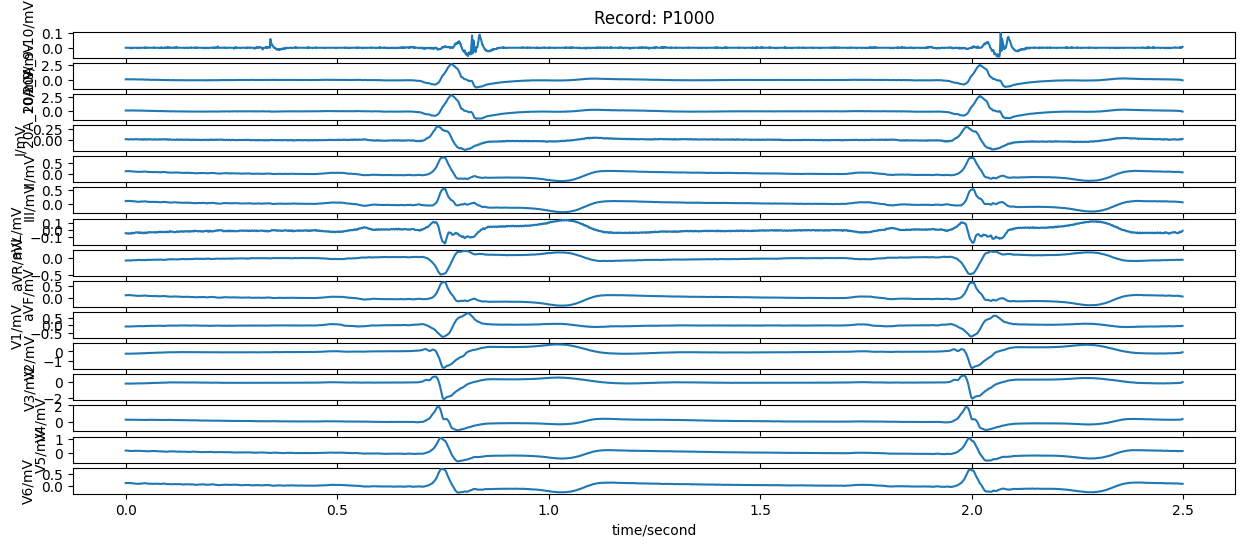

In [16]:
import matplotlib.pyplot as plt

wfdb.plot_wfdb(
    record=record,
    figsize=(15, 6)
)

plt.show()

In [17]:
annotation_files = list(ARGO_ROOT.rglob("*.annotation_consensus"))

print("Consensus annotation files:", len(annotation_files))

for file in annotation_files[:10]:
    print(file)

Consensus annotation files: 1962
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1000.annotation_consensus
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1002.annotation_consensus
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1003.annotation_consensus
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt1\P1004.

In [18]:
import sys
import torch

print("Python:")
print(sys.executable)

print("\nPyTorch:")
print(torch.__version__)

print("\nCUDA available:")
print(torch.cuda.is_available())

if torch.cuda.is_available():
    print("\nGPU:")
    print(torch.cuda.get_device_name(0))

    print("\nCUDA version:")
    print(torch.version.cuda)

Python:
d:\Sanika_EGM_Project\sanika_env\Scripts\python.exe

PyTorch:
2.11.0+cu128

CUDA available:
True

GPU:
NVIDIA GeForce RTX 4080 Laptop GPU

CUDA version:
12.8


In [19]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:")
print(PROJECT_ROOT)

DATA_ROOT = PROJECT_ROOT / "data" / "raw"

print("\nData root:")
print(DATA_ROOT)

print("\nContents:")
for item in DATA_ROOT.iterdir():
    print(item.name)


Project root:
d:\Sanika_EGM_Project

Data root:
d:\Sanika_EGM_Project\data\raw

Contents:
annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0
annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0.zip


In [20]:
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent

print("Project root:")
print(PROJECT_ROOT)

DATA_ROOT = PROJECT_ROOT / "data" / "raw"

print("\nData root:")
print(DATA_ROOT)

print("\nContents:")
for item in DATA_ROOT.iterdir():
    print(item.name)

Project root:
d:\Sanika_EGM_Project

Data root:
d:\Sanika_EGM_Project\data\raw

Contents:
annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0
annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0.zip


In [23]:
folders = [x for x in ARGO_ROOT.iterdir() if x.is_dir()]

print("Number of folders:", len(folders))

for folder in folders:
    print(folder.name)


Number of folders: 10
MATLAB_files
Pt1
Pt2
Pt3
Pt4
Pt5
Pt6
Pt7
Pt8
Pt9


In [24]:
pt7 = ARGO_ROOT / "Pt7"

print("Pt7 exists:", pt7.exists())

if pt7.exists():
    print("\nFiles in Pt7:\n")
   
    for file in pt7.iterdir():
        print(file.name)

Pt7 exists: True

Files in Pt7:

AblationPoints.txt
ConnectivityList.txt
MESHcoloring.txt
P1036.annotation_ann1
P1036.annotation_ann2
P1036.annotation_ann3
P1036.annotation_consensus
P1036.dat
P1036.hea
P1046.annotation_ann1
P1046.annotation_ann2
P1046.annotation_ann3
P1046.annotation_consensus
P1046.dat
P1046.hea
P105.annotation_ann1
P105.annotation_ann2
P105.annotation_ann3
P105.annotation_consensus
P105.dat
P105.hea
P1079.annotation_ann1
P1079.annotation_ann2
P1079.annotation_ann3
P1079.annotation_consensus
P1079.dat
P1079.hea
P1106.annotation_ann1
P1106.annotation_ann2
P1106.annotation_ann3
P1106.annotation_consensus
P1106.dat
P1106.hea
P1109.annotation_ann1
P1109.annotation_ann2
P1109.annotation_ann3
P1109.annotation_consensus
P1109.dat
P1109.hea
P1117.annotation_ann1
P1117.annotation_ann2
P1117.annotation_ann3
P1117.annotation_consensus
P1117.dat
P1117.hea
P1118.annotation_ann1
P1118.annotation_ann2
P1118.annotation_ann3
P1118.annotation_consensus
P1118.dat
P1118.hea
P1153.annota

In [25]:
if pt7.exists():
    for file in pt7.iterdir():
        if file.is_file():
            print(f"{file.name:40} {file.stat().st_size:,} bytes")

AblationPoints.txt                       1,729 bytes
ConnectivityList.txt                     214,694 bytes
MESHcoloring.txt                         109,424 bytes
P1036.annotation_ann1                    20 bytes
P1036.annotation_ann2                    14 bytes
P1036.annotation_ann3                    20 bytes
P1036.annotation_consensus               20 bytes
P1036.dat                                150,000 bytes
P1036.hea                                732 bytes
P1046.annotation_ann1                    14 bytes
P1046.annotation_ann2                    14 bytes
P1046.annotation_ann3                    14 bytes
P1046.annotation_consensus               14 bytes
P1046.dat                                150,000 bytes
P1046.hea                                702 bytes
P105.annotation_ann1                     14 bytes
P105.annotation_ann2                     14 bytes
P105.annotation_ann3                     14 bytes
P105.annotation_consensus                14 bytes
P105.dat                 

In [26]:
hea_files = list(pt7.glob("*.hea"))

print("HEA files:")
for file in hea_files:
    print(file)

HEA files:
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt7\P1036.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt7\P1046.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt7\P105.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\annotated-dataset-of-post-ischemic-ventricular-tachycardia-electrograms-argo-1.0.0\ARGODataset_Folder\Pt7\P1079.hea
d:\Sanika_EGM_Project\data\raw\annotated-dataset-of-post-ischemic-vent

In [27]:
if hea_files:
    hea_file = hea_files[0]

    print("\n----- HEADER -----\n")

    with open(hea_file, "r", errors="ignore") as f:
        print(f.read())


----- HEADER -----

P1036 15 1000 2500
P1036.dat 32 333.3333(0)/mV 0 0 2 -14 0 20A_15-16
P1036.dat 32 333.3333(0)/mV 0 0 -43 -4431 0 20A_15
P1036.dat 32 333.3333(0)/mV 0 0 -40 -2276 0 20A_16
P1036.dat 32 333.3333(0)/mV 0 0 35 -21826 0 I
P1036.dat 32 333.3333(0)/mV 0 0 -1 18571 0 II
P1036.dat 32 333.3333(0)/mV 0 0 -36 -25291 0 III
P1036.dat 32 333.3333(0)/mV 0 0 36 -31226 0 aVL
P1036.dat 32 333.3333(0)/mV 0 0 -17 -31389 0 aVR
P1036.dat 32 333.3333(0)/mV 0 0 -18 -3462 0 aVF
P1036.dat 32 333.3333(0)/mV 0 0 -67 -7350 0 V1
P1036.dat 32 333.3333(0)/mV 0 0 -1 -3821 0 V2
P1036.dat 32 333.3333(0)/mV 0 0 -23 -2881 0 V3
P1036.dat 32 333.3333(0)/mV 0 0 -6 1520 0 V4
P1036.dat 32 333.3333(0)/mV 0 0 0 3352 0 V5
P1036.dat 32 333.3333(0)/mV 0 0 -2 -2366 0 V6



In [28]:
annotation_files = list(pt7.glob("*.annotation_*"))

print("Annotation files:", len(annotation_files))

for file in annotation_files:
    print(file.name)

Annotation files: 304
P1036.annotation_ann1
P1036.annotation_ann2
P1036.annotation_ann3
P1036.annotation_consensus
P1046.annotation_ann1
P1046.annotation_ann2
P1046.annotation_ann3
P1046.annotation_consensus
P105.annotation_ann1
P105.annotation_ann2
P105.annotation_ann3
P105.annotation_consensus
P1079.annotation_ann1
P1079.annotation_ann2
P1079.annotation_ann3
P1079.annotation_consensus
P1106.annotation_ann1
P1106.annotation_ann2
P1106.annotation_ann3
P1106.annotation_consensus
P1109.annotation_ann1
P1109.annotation_ann2
P1109.annotation_ann3
P1109.annotation_consensus
P1117.annotation_ann1
P1117.annotation_ann2
P1117.annotation_ann3
P1117.annotation_consensus
P1118.annotation_ann1
P1118.annotation_ann2
P1118.annotation_ann3
P1118.annotation_consensus
P1153.annotation_ann1
P1153.annotation_ann2
P1153.annotation_ann3
P1153.annotation_consensus
P1154.annotation_ann1
P1154.annotation_ann2
P1154.annotation_ann3
P1154.annotation_consensus
P1160.annotation_ann1
P1160.annotation_ann2
P1160.an

In [29]:
for file in annotation_files:
    print("\n==============================")
    print(file.name)
    print("==============================")

    with open(file, "r", errors="ignore") as f:
        text = f.read()

    print(text[:2000])


P1036.annotation_ann1
 ì  Ò œüA K üA   

P1036.annotation_ann2
 ì  ' XüU   

P1036.annotation_ann3
 ì  Â œüA n üA   

P1036.annotation_consensus
 ì  Â œüA n üA   

P1046.annotation_ann1
 ì  ' XüU   

P1046.annotation_ann2
 ì  ' XüP   

P1046.annotation_ann3
 ì  ' XüU   

P1046.annotation_consensus
 ì  ' XüP   

P105.annotation_ann1
 ì  ' XüP   

P105.annotation_ann2
 ì  ' XüU   

P105.annotation_ann3
 ì  ' XüU   

P105.annotation_consensus
 ì  ' XüU   

P1079.annotation_ann1
 ì  ' XüU   

P1079.annotation_ann2
 ì  ' XüU   

P1079.annotation_ann3
 ì  Ï œüA T üA   

P1079.annotation_consensus
 ì  ' XüU   

P1106.annotation_ann1
 ì  ' XüU   

P1106.annotation_ann2
 ì  ' XüU   

P1106.annotation_ann3
 ì  Æ œüA \ üA   

P1106.annotation_consensus
 ì  ' XüU   

P1109.annotation_ann1
 ì  ' XüP   

P1109.annotation_ann2
 ì  ' XüP   

P1109.annotation_ann3
 ì  ' XüP   

P1109.annotation_consensus
 ì  ' XüP   

P1117.annotation_ann1
 ì  ' X